# 01 Data exploration: what the magnetic data look like

**Question.** Which properties of the IPP 1 magnetic data (COMPASS tokamak, 24 magnetic measurements, 31 shape
parameters) decide how we must train and score a model? We look at the structure, the missing targets, the
redundancy of the inputs, the uneven distribution of shapes, the added noise in the second file, and we show on
a small experiment why the split must be by whole discharges.

The raw data are confidential. This notebook only prints summary statistics and draws plots, never raw rows.

Runtime: under 1 minute (6 s measured, 2 CPU threads); needs only the raw data `equil_data.csv` and `equil_data_noisy.csv` (README, "Setup and run").

In [1]:
import os, sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The data: HACKATHON_HOME, else the repository itself when it has a data/ folder, else the parent folder of the repository.
here = Path.cwd().resolve()
repo = next((p for p in [here, *here.parents] if (p / "analysis" / "common.py").exists()), None)
if repo is None:
    raise SystemExit("Run from inside the repository")
os.environ.setdefault("HACKATHON_HOME", str(repo if (repo / "data").is_dir() else repo.parent))
sys.path.insert(0, str(repo / "analysis"))
import torch
torch.set_num_threads(2)
import common as C

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
print("raw data folder found:", C.DATA.exists(), "| results folder found:", C.OUT.exists())

raw data folder found: True | results folder found: True


## 1. Size and structure

In [2]:
df, X, Y, G, M = C.load()
x_cols = [c for c in df.columns if c.startswith(("IPR", "FL"))]
per = df.groupby("discharge").size()
srt = df.sort_values(["discharge", "time"])
step = srt.groupby("discharge").time.diff().dropna()
J = {t: i for i, t in enumerate(C.TARGETS)}
KEY = {}
KEY["rows"] = int(len(df)); KEY["columns"] = int(df.shape[1]); KEY["inputs"] = len(x_cols)
KEY["discharges"] = int(df.discharge.nunique())
KEY["rows_per_discharge"] = [int(per.min()), float(per.median()), int(per.max())]
KEY["time_range"] = [float(df.time.min()), float(df.time.max())]
KEY["median_time_step"] = float(step.median())
KEY["missing_inputs"] = int(df[x_cols].isna().sum().sum())
print(f"rows {KEY['rows']}, columns {KEY['columns']}, inputs {KEY['inputs']}, modelled targets {len(C.TARGETS)}")
print(f"discharges {KEY['discharges']}; rows per discharge min / median / max = {KEY['rows_per_discharge']}")
print(f"relative time runs from {KEY['time_range'][0]} to {KEY['time_range'][1]}; median step {KEY['median_time_step']:.4f} (fraction of the discharge)")
print("missing values among the 24 inputs:", KEY["missing_inputs"])

rows 42972, columns 57, inputs 24, modelled targets 16
discharges 149; rows per discharge min / median / max = [17, 293.0, 439]
relative time runs from 0.0 to 1.0; median step 0.0030 (fraction of the discharge)
missing values among the 24 inputs: 0


One row is one instant of one discharge. Rows of one discharge are near copies of each other, which matters for the
split (section 8). `time` runs from 0 to 1 inside each discharge, so it is a relative time. Input units are those of the file (the organizers do not state them); every model standardizes the inputs first.

## 2. The 24 inputs (summary statistics only)

In [3]:
print(df[x_cols].describe().T[["min", "mean", "max", "std"]].round(4).to_string())

          min    mean     max     std
IPR01 -0.2662 -0.1317  0.2664  0.0974
IPR02 -0.2511 -0.1273  0.2497  0.0924
IPR03 -0.2351 -0.1158  0.2223  0.0836
IPR04 -0.1670 -0.0748  0.1464  0.0530
IPR05 -0.1260 -0.0500  0.1034  0.0351
IPR06 -0.1115 -0.0190  0.0882  0.0171
IPR07 -0.2338 -0.0789  0.1892  0.0586
IPR08 -0.3374 -0.1578  0.3298  0.1177
IPR09 -0.5651 -0.2587  0.5536  0.1978
IPR10 -0.3555 -0.1503  0.3276  0.1127
IPR11 -0.2115 -0.0747  0.1718  0.0563
IPR12 -0.1088 -0.0193  0.0856  0.0175
IPR13 -0.0739  0.0162  0.0818  0.0344
IPR14 -0.1338 -0.0558  0.1210  0.0400
IPR15 -0.2561 -0.1185  0.2399  0.0866
IPR16 -0.2926 -0.1438  0.2937  0.1065
FL01  -0.3119  0.0707  0.3345  0.1426
FL02  -0.2972  0.0482  0.3059  0.1343
FL03  -0.2944  0.0506  0.3042  0.1378
FL04  -0.2940  0.0616  0.3017  0.1433
FL05  -0.2940  0.0615  0.3019  0.1432
FL06  -0.2955  0.0504  0.2998  0.1373
FL07  -0.2987  0.0428  0.3016  0.1326
FL08  -0.3197  0.0852  0.3442  0.1482


## 3. The targets: which exist where, and how large is their spread

Some targets exist only in one plasma configuration. We check exactly how the missing values are written, because a
masked loss must ignore them (and must not treat them as zeros).

In [4]:
rows = []
for t in C.TARGETS:
    scale, unit = C.UNIT[t]
    v = Y[M[:, J[t]], J[t]] * scale
    rows.append(dict(target=t, unit=unit or "-", present=M[:, J[t]].mean(), mean=v.mean(), std=v.std(), min=v.min(), max=v.max()))
print(pd.DataFrame(rows).set_index("target").round(4).to_string())

lim = Y[:, J["is_limited"]] > 0.5
KEY["limited_share"] = float(lim.mean())
for t in ("R_limiter", "Z_limiter"):
    KEY[f"{t}_present_equals_limited"] = float((M[:, J[t]] == lim).mean())
for t in ("R_x_point", "Z_x_point", "R_strike_point_1", "R_strike_point_2"):
    KEY[f"{t}_present_equals_divertor"] = float((M[:, J[t]] == ~lim).mean())
KEY["rows_missing_in_always_present_targets"] = int((~M[:, J["plasma_current"]]).sum())
KEY["negative_current_share"] = float(np.nanmean(Y[:, J["plasma_current"]] < 0))
print()
print(f"rows with a missing plasma_current (and elongation, triangularity): {KEY['rows_missing_in_always_present_targets']}")
print(f"limited rows: {lim.mean():.3f}; plasma current negative in {KEY['negative_current_share']:.3f} of the rows")
for k, v in KEY.items():
    if "present_equals" in k:
        print(f"  share of rows where '{k.split('_present')[0]}' is present exactly as expected: {v:.4f}")

                    unit  present        mean         std         min         max
target                                                                           
plasma_current        kA   1.0000 -157.565002  114.184402 -318.382904  318.450195
R_mag_axis            mm   1.0000  561.100403    8.021600  462.312988  674.115417
Z_mag_axis            mm   1.0000   16.685900   13.741100 -197.908997  143.143295
elongation             -   1.0000    1.616300    0.270600    0.886500    1.893700
triangularity          -   1.0000    0.305400    0.119400   -0.052100    0.527500
triangularity_upper    -   1.0000    0.204100    0.074900   -0.096400    0.469100
triangularity_lower    -   1.0000    0.406600    0.172400   -0.072100    0.729500
R_x_point             mm   0.5576  463.161987    8.056300  409.965210  482.795593
Z_x_point             mm   0.5576 -328.587402   12.736700 -357.898407 -280.186401
R_strike_point_1      mm   0.5573  433.612000   12.552200  393.683990  476.435791
Z_strike_point_1

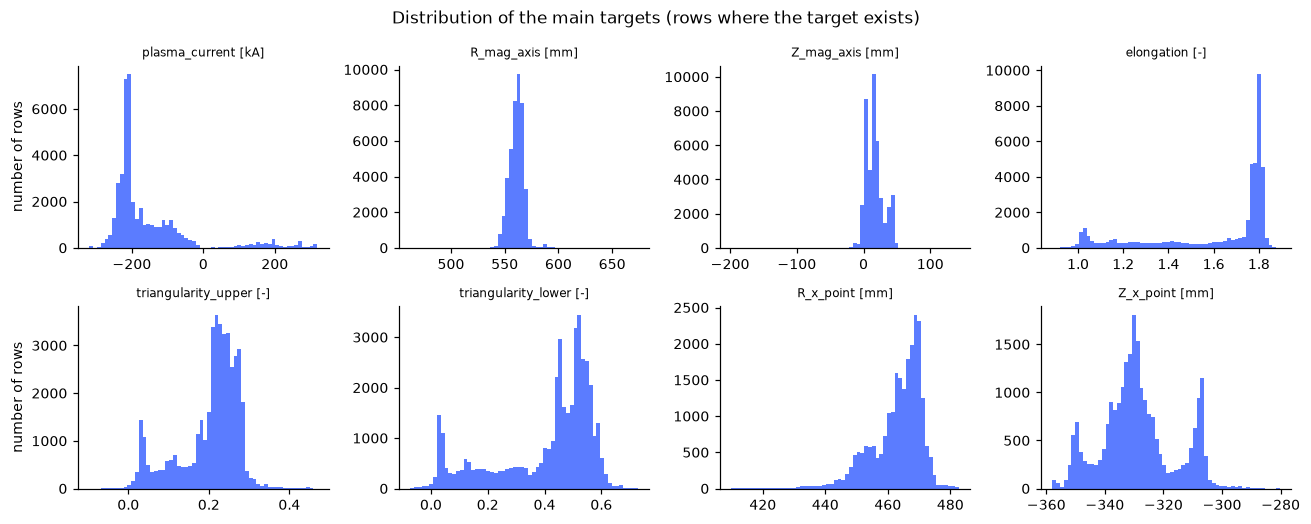

In [5]:
fig, ax = plt.subplots(2, 4, figsize=(12, 4.8))
for a, t in zip(ax.ravel(), ["plasma_current", "R_mag_axis", "Z_mag_axis", "elongation", "triangularity_upper", "triangularity_lower", "R_x_point", "Z_x_point"]):
    scale, unit = C.UNIT[t]
    a.hist(Y[M[:, J[t]], J[t]] * scale, bins=60, color="#5b7cff")
    a.set_title(f"{t} [{unit or '-'}]", fontsize=8)
for a in ax[:, 0]:
    a.set_ylabel("number of rows")
fig.suptitle("Distribution of the main targets (rows where the target exists)")
fig.tight_layout(); plt.show()

The histograms are far from flat: many values pile up in a narrow band. Section 5 puts a number on it.

## 4. The inputs are highly redundant

Principal components of the 24 standardized inputs show how much of the variance lies in a few directions.

cumulative explained variance of the first 8 components: [0.62181 0.92779 0.98239 0.99428 0.99925 0.99958 0.99985 0.99992]
components needed for 99.9 % of the variance: 5


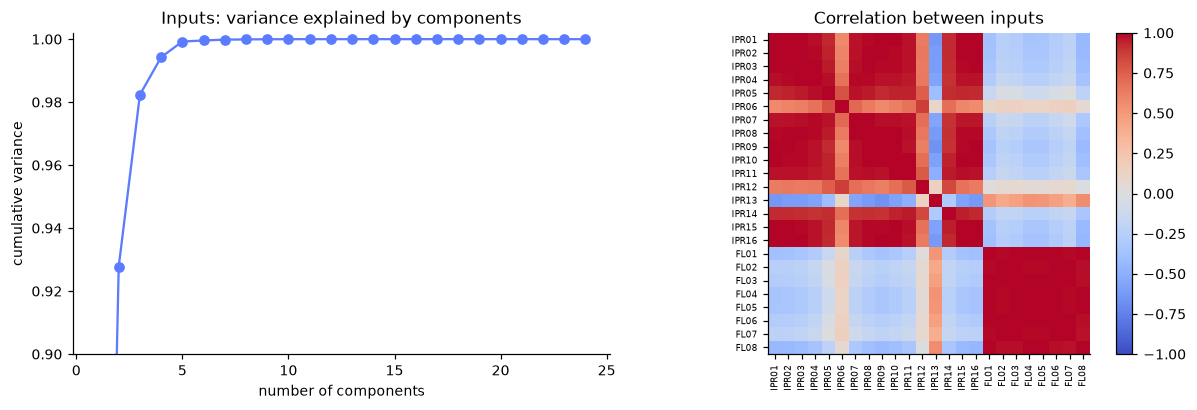

In [6]:
Z = ((X - X.mean(0)) / X.std(0)).astype(np.float64)
ev = np.linalg.svd(Z, compute_uv=False) ** 2
ev /= ev.sum()
cum = np.cumsum(ev)
KEY["pca_components_for_99_9pct"] = int(np.searchsorted(cum, 0.999) + 1)
KEY["pca_cumulative_first5"] = [round(float(v), 5) for v in cum[:5]]
print("cumulative explained variance of the first 8 components:", np.round(cum[:8], 5))
print("components needed for 99.9 % of the variance:", KEY["pca_components_for_99_9pct"])

corr = np.corrcoef(Z.T)
off = corr[np.triu_indices(24, 1)]
KEY["input_abs_corr_median"] = float(np.median(np.abs(off)))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(range(1, 25), cum, marker="o", color="#5b7cff")
ax[0].set_ylim(0.9, 1.002); ax[0].set_xlabel("number of components"); ax[0].set_ylabel("cumulative variance")
ax[0].set_title("Inputs: variance explained by components")
im = ax[1].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax[1].set_xticks(range(24)); ax[1].set_xticklabels(x_cols, rotation=90, fontsize=6)
ax[1].set_yticks(range(24)); ax[1].set_yticklabels(x_cols, fontsize=6)
ax[1].set_title("Correlation between inputs")
fig.colorbar(im, ax=ax[1], fraction=0.046); fig.tight_layout(); plt.show()

## 5. Shapes are correlated, and a few rows dominate

Elongation and triangularity lie on a narrow curve, so the data contain few unusual shapes (the 18 discharges with low elongation are examined in notebook 07). A density plot
(2D histogram, no single rows) shows it.

elongation range 0.887 to 1.894; the 3 fullest of 40 equal-width bins hold 0.56 of all rows
correlation elongation vs triangularity 0.976


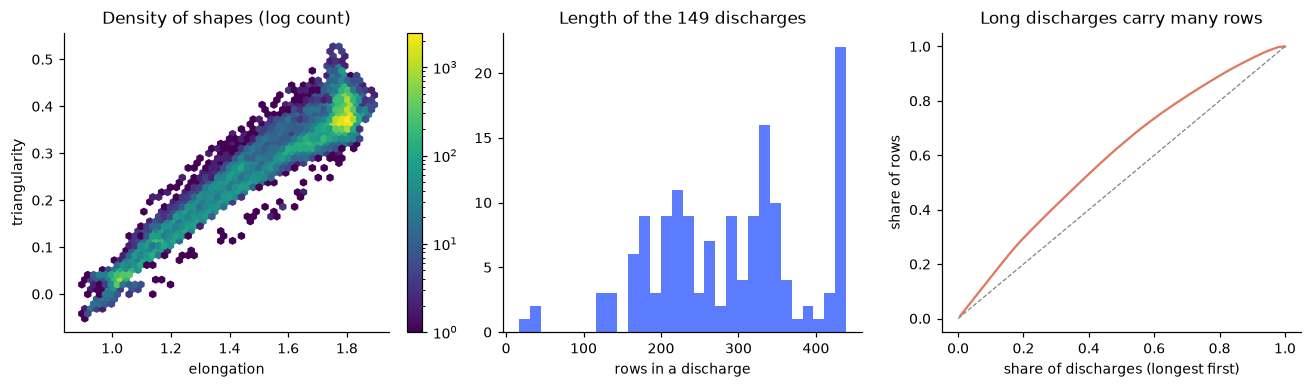

the longest 10 % of discharges hold 0.15 of all rows


In [7]:
ok = M[:, J["elongation"]] & M[:, J["triangularity"]]
el, tr = Y[ok, J["elongation"]], Y[ok, J["triangularity"]]
KEY["corr_elongation_triangularity"] = float(np.corrcoef(el, tr)[0, 1])
hist, edges = np.histogram(el, bins=40)
KEY["elongation_top3_bins_of_40_share"] = float(np.sort(hist)[-3:].sum() / len(el))
KEY["elongation_range"] = [float(el.min()), float(el.max())]
print(f"elongation range {el.min():.3f} to {el.max():.3f}; the 3 fullest of 40 equal-width bins hold {KEY['elongation_top3_bins_of_40_share']:.2f} of all rows")
print(f"correlation elongation vs triangularity {KEY['corr_elongation_triangularity']:.3f}")
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
h = ax[0].hexbin(el, tr, gridsize=50, bins="log", cmap="viridis", mincnt=1)
ax[0].set_xlabel("elongation"); ax[0].set_ylabel("triangularity"); ax[0].set_title("Density of shapes (log count)")
fig.colorbar(h, ax=ax[0], fraction=0.046)
ax[1].hist(per.values, bins=30, color="#5b7cff"); ax[1].set_xlabel("rows in a discharge"); ax[1].set_title("Length of the 149 discharges")
top = per.sort_values(ascending=False)
KEY["top10pct_discharges_row_share"] = float(top.iloc[: int(round(0.1 * len(top)))].sum() / top.sum())
ax[2].plot(np.arange(1, len(top) + 1) / len(top), np.cumsum(top.values) / top.sum(), color="#e07a5f")
ax[2].plot([0, 1], [0, 1], color="grey", lw=0.8, ls="--")
ax[2].set_xlabel("share of discharges (longest first)"); ax[2].set_ylabel("share of rows"); ax[2].set_title("Long discharges carry many rows")
fig.tight_layout(); plt.show()
print(f"the longest 10 % of discharges hold {KEY['top10pct_discharges_row_share']:.2f} of all rows")

## 6. One discharge in time

The discharge with the median number of rows is drawn; blue marks the rows where the plasma touches the limiter.

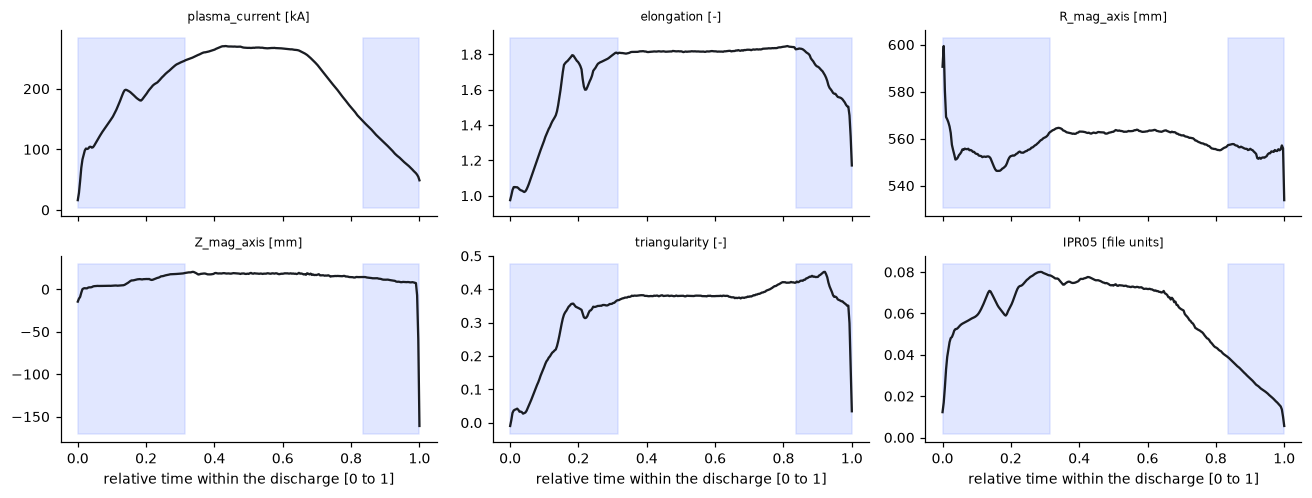

In [8]:
g = per.index[np.argsort(per.values, kind="stable")[len(per) // 2]]
d = df[df.discharge == g].sort_values("time")
fig, ax = plt.subplots(2, 3, figsize=(12, 4.6), sharex=True)
for a, c in zip(ax.ravel(), ["plasma_current", "elongation", "R_mag_axis", "Z_mag_axis", "triangularity", "IPR05"]):
    scale = C.UNIT.get(c, (1.0, ""))[0]
    a.plot(d.time, d[c] * scale, color="#1a1d23")
    lo, hi = a.get_ylim()
    a.fill_between(d.time, lo, hi, where=d.is_limited.astype(bool), color="#8aa0ff", alpha=0.25)
    a.set_title(f"{c} [{C.UNIT.get(c, (1, 'file units'))[1] or '-'}]", fontsize=8)
for a in ax[1]:
    a.set_xlabel("relative time within the discharge [0 to 1]")
fig.tight_layout(); plt.show()
KEY["median_discharge_rows"] = int(len(d))

## 7. The noisy file

`equil_data_noisy.csv` has the same rows and the same reference values (labels); only the inputs are changed. We measure how
large the change is relative to each input's spread and whether it looks like a drift in time. A control (the same
noise with its rows shuffled inside each discharge) shows what a pure random noise would give.

same rows in both files: True | targets identical: True
noise std / signal std per input (min, median, max): [0.086 0.155 0.167]
mean |correlation of the noise with time| inside a discharge: 0.050; shuffled control 0.052


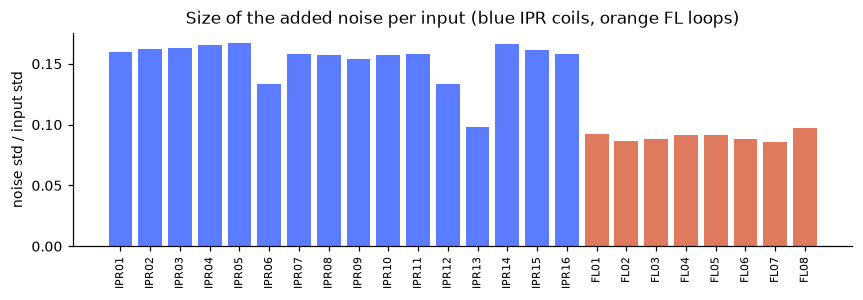

In [9]:
dn, Xn, Yn, Gn, Mn = C.load(noisy=True)
KEY["same_rows"] = bool(np.array_equal(dn.discharge.values, df.discharge.values) and np.allclose(dn.time.values, df.time.values))
KEY["targets_identical"] = bool(np.allclose(np.nan_to_num(Y, nan=-999), np.nan_to_num(Yn, nan=-999)))
noise = (Xn - X).astype(np.float64)
ratio = noise.std(0) / X.std(0)
KEY["noise_over_signal_std"] = [float(ratio.min()), float(np.median(ratio)), float(ratio.max())]
rng = np.random.default_rng(0)
t_all = df.time.values.astype(np.float64)


def mean_abs_corr_with_time(nz):
    out = []
    for idx in df.groupby("discharge").indices.values():
        if len(idx) < 6:
            continue
        tc = t_all[idx] - t_all[idx].mean()
        nc = nz[idx] - nz[idx].mean(0)
        c = (tc @ nc) / (np.sqrt((tc ** 2).sum()) * np.sqrt((nc ** 2).sum(0)) + 1e-12)
        out.append(np.abs(c).mean())
    return float(np.mean(out))


shuffled = noise.copy()
for idx in df.groupby("discharge").indices.values():
    shuffled[idx] = noise[rng.permutation(idx)]
KEY["noise_abs_corr_with_time"] = mean_abs_corr_with_time(noise)
KEY["noise_abs_corr_with_time_shuffled_control"] = mean_abs_corr_with_time(shuffled)
print("same rows in both files:", KEY["same_rows"], "| targets identical:", KEY["targets_identical"])
print("noise std / signal std per input (min, median, max):", np.round(KEY["noise_over_signal_std"], 3))
print(f"mean |correlation of the noise with time| inside a discharge: {KEY['noise_abs_corr_with_time']:.3f}; shuffled control {KEY['noise_abs_corr_with_time_shuffled_control']:.3f}")
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.bar(range(24), ratio, color=["#5b7cff" if c.startswith("IPR") else "#e07a5f" for c in x_cols])
ax.set_xticks(range(24)); ax.set_xticklabels(x_cols, rotation=90, fontsize=7)
ax.set_ylabel("noise std / input std"); ax.set_title("Size of the added noise per input (blue IPR coils, orange FL loops)")
fig.tight_layout(); plt.show()

## 8. Why the split must be by whole discharges

A 1-nearest-neighbor regressor on the standardized inputs predicts `R_mag_axis`. With a random split by rows a test row
almost always has a near copy of itself from the same discharge in the training set. With a split by discharge it does
not. The gap shows how much a row split would flatter any model. (The protocol everywhere else is GroupKFold by discharge.)

1-NN R_mag_axis MAE: random row split 0.617 mm, split by discharge 2.027 mm


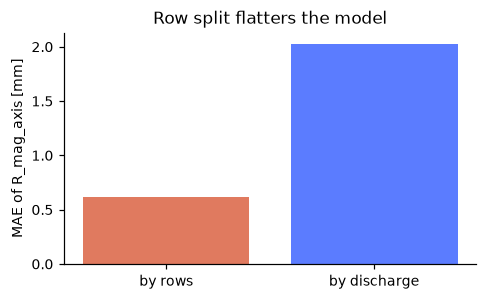

In [10]:
from sklearn.model_selection import GroupKFold, KFold
from sklearn.neighbors import KNeighborsRegressor

jr = J["R_mag_axis"]
Zs = ((X - X.mean(0)) / X.std(0)).astype(np.float32)


def knn_mae(splits):
    errs = []
    for tr_i, te_i in splits:
        m = KNeighborsRegressor(n_neighbors=1, algorithm="brute").fit(Zs[tr_i], Y[tr_i, jr])
        errs.append(np.abs(m.predict(Zs[te_i]) - Y[te_i, jr]).mean() * 1000)
    return float(np.mean(errs))


KEY["knn_mae_mm_row_split"] = knn_mae(KFold(5, shuffle=True, random_state=0).split(Zs))
KEY["knn_mae_mm_discharge_split"] = knn_mae(GroupKFold(5).split(Zs, groups=G))
print(f"1-NN R_mag_axis MAE: random row split {KEY['knn_mae_mm_row_split']:.3f} mm, split by discharge {KEY['knn_mae_mm_discharge_split']:.3f} mm")
fig, ax = plt.subplots(figsize=(4.5, 2.8))
ax.bar(["by rows", "by discharge"], [KEY["knn_mae_mm_row_split"], KEY["knn_mae_mm_discharge_split"]], color=["#e07a5f", "#5b7cff"])
ax.set_ylabel("MAE of R_mag_axis [mm]"); ax.set_title("Row split flatters the model")
fig.tight_layout(); plt.show()

## Conclusions

- **Size.** 42,972 rows from 149 discharges (17 to 439 rows each, median 293), 24 inputs with no missing value, and `time` is a relative time from 0 to 1. The actual time between two rows is not in the file (`time` is relative), so nothing in this repository is a statement in milliseconds per row (open question for the organizers).
- **Missing targets are structural, so the loss must be masked.** `R_x_point` and `Z_x_point` exist exactly in the divertor rows, `R_limiter` and `Z_limiter` exactly in the limited rows (44.2 % of all rows are limited). The strike points follow the divertor configuration in all rows except 11. One row lacks `plasma_current`, `elongation` and the triangularities. The plasma current is negative in 92.6 % of the rows, so its sign must be kept. `Z_x_point` lies between -358 and -280 mm in every divertor row, so the X point is always the lower one (lower single null); the data hold no upper X point and no double null, so nothing is known about them.
- **The inputs are redundant in variance.** The first 5 principal components of the 24 inputs hold 99.93 % of the variance (5 components reach 99.9 %), and the median absolute correlation between two inputs is 0.57. This is not the same as redundant information: a network that sees only those 5 components has a radial axis error of 2.63 mm against 0.41 mm with all 24 inputs (same folds and seed, `results/data-checks.md`). Notebook 03 tests fewer sensors directly.
- **Shapes are uneven and strongly correlated.** Elongation runs from 0.89 to 1.89 (values below 1 are unusual for a tokamak plasma and the organizers' formula is not recorded here, so we do not interpret those rows; to be checked with the institute), its correlation with triangularity is 0.976, and the 3 fullest of 40 equal-width bins hold 56 % of the rows. The longest 10 % of discharges hold 15 % of the rows, so long discharges weigh more in training and scoring (see notebook 02 for the error on rare shapes).
- **The spread is small only for the axis, the X point and the strike points** (standard deviation 2.4 to 13.7 mm); the limiter point has 90 mm (R) and 153 mm (Z) and the plasma current 114 kA, so errors are given in physical units and next to the spread of each target.
- **The noisy file** has the same rows and identical reference values. The standard deviation of the added noise is 8.6 % to 16.7 % of the standard deviation of each input (median 15.5 %; about 9 % for the flux loops and 16 % for the coils). The noise is white (lag-1 autocorrelation -0.004, `results/data-checks.md`) and shows no measurable drift: its mean absolute correlation with time inside a discharge is 0.050, the same as for the shuffled control (0.052). The narrow range of the ratio suggests that the noise was added in proportion to each input (our inference, not confirmed) and its size may be larger than the noise of real probes (to be checked with the institute), so errors on this file are a stress test, not an expected operating accuracy. Every drift result in notebook 08 uses a drift we generated.
- **Split by whole discharges is necessary.** A 1-nearest-neighbor model has an `R_mag_axis` error of 0.62 mm with a random row split and 2.03 mm with a split by discharge, a factor of 3.3. A row split would make this model look about 3 times better than it is, and other models are likely flattered too. Random group folds are still optimistic for a later campaign: the discharge numbers appear to follow time (not confirmed with the organizers) and on higher-numbered discharges the error is larger (notebooks 08 and 09).

*The conclusions above were typed from the outputs of the stored run and differ slightly after a rerun.*

**Answer.** Split by whole discharges (a row split flatters a nearest-neighbor model about 3.3 times), mask the targets that do not exist (they are missing exactly in the other configuration), give errors in mm and kA next to the spread of each target, and treat the redundancy of the inputs as redundancy in variance only: 5 components hold 99.93 % of the variance, yet a network on them has 2.63 mm radial axis error against 0.41 mm. The provided noisy file is white noise with no measurable drift.